### Аномалии госпитализаций

Начнём с двух признаков: числа лабораторных процедур и числа лекарств. Проверим, какие госпитализации выглядят необычно среди записей той же длительности.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import RobustScaler

#### Обучающая выборка и проверка значений

In [2]:
'''загрузка данных'''
data_dir = Path("data/raw")
if not data_dir.is_dir():
    data_dir = Path("../data/raw")

encounters = pd.read_csv(
    data_dir / "diabetic_data.csv",
    keep_default_na=False,
    na_values=["?"],
    dtype={
        "diag_1": "string",
        "diag_2": "string",
        "diag_3": "string",
        "payer_code": "string",
    },)

death_codes = {11, 19, 20, 21}
cohort = encounters.loc[
    ~encounters["discharge_disposition_id"].isin(death_codes)].copy()
cohort["readmitted_30d"] = cohort["readmitted"].eq("<30").astype(int)

groups = cohort["patient_nbr"]
train_idx, holdout_idx = next(
    GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42).split(cohort, groups=groups)
)
train = cohort.iloc[train_idx].copy()
assert len(train) == 69_944 and train["patient_nbr"].nunique() == 49_307
assert set(train["patient_nbr"]).isdisjoint(cohort.iloc[holdout_idx]["patient_nbr"])

features = {"num_lab_procedures": "лабораторные процедуры", "num_medications": "лекарства"}
duration = "time_in_hospital"
values = train[[duration, *features]]
audit = pd.DataFrame({
    "пропуски": values.isna().sum(),
    "отрицательные": values.lt(0).sum(),
    "минимум": values.min(),
    "максимум": values.max(),
})
print(audit.to_string())
assert values.notna().all().all() and values.ge(0).all().all()
assert values[duration].between(1, 14).all()


                    пропуски  отрицательные  минимум  максимум
time_in_hospital           0              0        1        14
num_lab_procedures         0              0        1       132
num_medications            0              0        1        81


#### Общий порог и порог по длительности

Берём 99-й процентиль для каждого признака по всему `train` и отдельно для каждой длительности. Отмечаем значения строго выше порога. Из-за целочисленных значений и совпадений на границе доля отмеченных строк может отличаться от 1%.

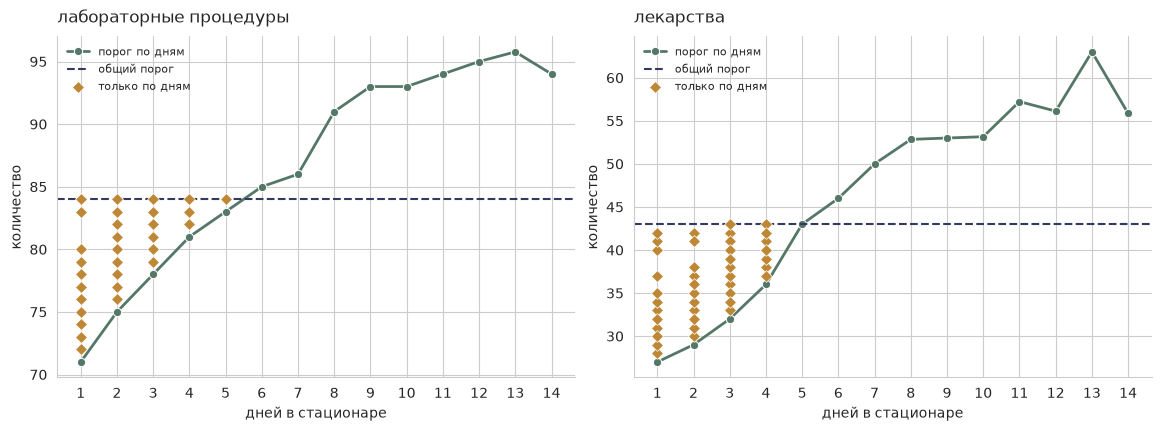

In [3]:
global_threshold = train[list(features)].quantile(0.99)
daily_threshold = train.groupby(duration)[list(features)].quantile(0.99)
daily_sizes = train[duration].value_counts().sort_index()
assert daily_sizes.sum() == len(train)

with sns.axes_style("whitegrid", {"axes.grid.axis": "y"}):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout="constrained")
    for (feature, label), ax in zip(features.items(), axes, strict=True):
        threshold = train[duration].map(daily_threshold[feature])
        only_context = train.loc[
            train[feature].gt(threshold) & train[feature].le(global_threshold[feature])
        ]
        sns.lineplot(x=daily_threshold.index, y=daily_threshold[feature], marker="o",
                     color="#557768", linewidth=2, label="порог по дням", ax=ax)
        ax.axhline(global_threshold[feature], color="#34395F", linestyle="--", label="общий порог")
        sns.scatterplot(data=only_context[[duration, feature]].drop_duplicates(),
                        x=duration, y=feature, marker="D", s=36, color="#BD8736",
                        label="только по дням", ax=ax, zorder=4)
        ax.set_title(label, loc="left", pad=10)
        ax.set(xlabel="дней в стационаре", ylabel="количество", xticks=daily_sizes.index)
        ax.legend(frameon=False, fontsize=8)
    sns.despine(fig=fig)
plt.show()


#### Какие госпитализации нашли правила

In [4]:
for feature, label in features.items():
    threshold = train[duration].map(daily_threshold[feature])
    above_global = train[feature].gt(global_threshold[feature])
    above_daily = train[feature].gt(threshold)
    flags = {
        "только общий порог": above_global & ~above_daily,
        "только порог по дням": above_daily & ~above_global,
        "оба порога": above_global & above_daily,
        "ни один порог": ~above_global & ~above_daily,
    }
    assert pd.DataFrame(flags).sum(axis=1).eq(1).all()
    print(label)
    summary = pd.DataFrame({
        group: {"строки": mask.sum(), "доля <30": train.loc[mask, "readmitted_30d"].mean()}
        for group, mask in flags.items()
    }).T
    print(summary.to_string(formatters={"строки": "{:.0f}".format, "доля <30": "{:.1%}".format}))

    examples = pd.concat([
        train.loc[mask, ["encounter_id", duration, feature, "readmitted"]]
        .assign(группа=group, порог_по_дням=threshold, строк_для_дня=train[duration].map(daily_sizes))
        .sort_values([feature, "encounter_id"], ascending=[False, True]).head(2)
        for group, mask in flags.items() if group != "ни один порог"
    ])

    display(examples.round({"порог_по_дням": 2}).reset_index(drop=True))


лабораторные процедуры
                     строки доля <30
только общий порог      316    13.3%
только порог по дням    314     8.6%
оба порога              336    11.9%
ни один порог         68978    11.3%


,encounter_id,time_in_hospital,num_lab_procedures,readmitted,группа,порог_по_дням,строк_для_дня
0,7111506,12,95,>30,только общий порог,95.00,989
1,34161666,12,95,>30,только общий порог,95.00,989
2,5293998,2,84,>30,только порог по дням,75.00,11793
3,12567660,3,84,<30,только порог по дням,78.00,12320
4,238167534,8,132,<30,оба порога,91.00,3017
5,52701030,13,129,>30,оба порога,95.77,824


лекарства
                     строки доля <30
только общий порог      357    13.7%
только порог по дням    306    10.5%
оба порога              304     9.5%
ни один порог         68977    11.3%


,encounter_id,time_in_hospital,num_medications,readmitted,группа,порог_по_дням,строк_для_дня
0,66619254,13,63,NO,только общий порог,63.00,824
1,300823706,13,63,NO,только общий порог,63.00,824
2,27777342,4,43,NO,только порог по дням,36.00,9542
3,28032552,4,43,NO,только порог по дням,36.00,9542
4,135412542,10,81,<30,оба порога,53.15,1586
5,137878980,12,79,NO,оба порога,56.12,989


**вывод.** Порог по длительности отметил дополнительно 314 госпитализаций по числу анализов и 306 по числу лекарств. Например, 84 анализа за два дня превышают порог для двух дней (75), но укладываются в общий порог (84). Точки на графике показывают уникальные сочетания длительности и количества.

### Локальные аномалии и сравнение методов

#### Число соседей и совпадения на пороге

LOF сравнивает плотность вокруг госпитализации с плотностью вокруг её соседей. Используем семь числовых признаков из основного EDA. Масштабируем признаки на `train` через RobustScaler и сравниваем 15, 30 и 60 соседей. Основной вариант использует 30 соседей. Все методы отмечают по 1% строк. При одинаковых оценках используем один порядок строк с фиксированным seed.

In [5]:
anomaly_columns = [
    "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
    "number_inpatient", "number_emergency", "number_outpatient",
]
anomaly_features = train[anomaly_columns]
low, high = anomaly_features.quantile(0.01), anomaly_features.quantile(0.99)
span = (high - low).clip(lower=1)
quantile_score = pd.concat([
    (low - anomaly_features).div(span),
    (anomaly_features - high).div(span),
], axis=1).max(axis=1).clip(lower=0)

forest = IsolationForest(n_estimators=150, random_state=42, n_jobs=-1)
forest.fit(anomaly_features)
forest_score = pd.Series(-forest.score_samples(anomaly_features), index=train.index)

n_flagged = round(0.01 * len(train))
tie_order = train.sample(frac=1, random_state=42).index

assert anomaly_features.notna().all().all()
scaler = RobustScaler()
scaled_features = scaler.fit_transform(anomaly_features)
iqr = anomaly_features.quantile(0.75) - anomaly_features.quantile(0.25)
print("признаки с нулевым IQR (RobustScaler оставляет масштаб 1):",
      ", ".join(iqr.index[iqr.eq(0)]) or "нет")
print(f"строк с повторяющимся набором признаков: {anomaly_features.duplicated(keep=False).sum():,}")

lof_scores = {}
for neighbors in (15, 30, 60):
    lof = LocalOutlierFactor(n_neighbors=neighbors, n_jobs=-1)
    lof.fit_predict(scaled_features)
    lof_scores[neighbors] = pd.Series(-lof.negative_outlier_factor_, index=train.index)

def top_rows(score):
    return score.reindex(tie_order).nlargest(n_flagged).index

lof_top = {neighbors: top_rows(score) for neighbors, score in lof_scores.items()}
sensitivity = []
for neighbors, score in lof_scores.items():
    selected = lof_top[neighbors]
    cutoff = score.loc[selected].min()
    sensitivity.append({
        "соседей": neighbors,
        "совпали с LOF 30": len(selected.intersection(lof_top[30])),
        "строк с баллом на границе": score.eq(cutoff).sum(),
        "из них в топе": score.loc[selected].eq(cutoff).sum(),
    })
print(pd.DataFrame(sensitivity).to_string(index=False))


признаки с нулевым IQR (RobustScaler оставляет масштаб 1): number_emergency, number_outpatient
строк с повторяющимся набором признаков: 22,590


/Users/flexonafft/cu-ml-diabetes-project/.venv/lib/python3.14/site-packages/sklearn/neighbors/_lof.py:327: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


 соседей  совпали с LOF 30  строк с баллом на границе  из них в топе
      15               429                          1              1
      30               699                          1              1
      60               501                          1              1


#### Пересечения и примеры, найденные только LOF

                                   строки доля_ранних_повторов
методы                                                        
LOF                                   596                11.4%
квантили                              362                22.4%
Isolation Forest                      326                27.0%
квантили + Isolation Forest           283                30.7%
Isolation Forest + LOF                 49                16.3%
квантили + Isolation Forest + LOF      41                24.4%
квантили + LOF                         13                23.1%


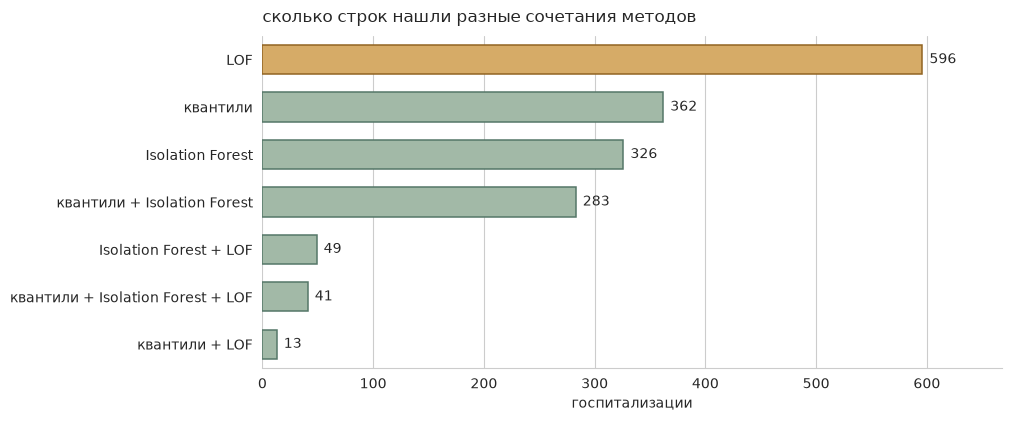

только LOF, без превышения порогов по дням: 423


,encounter_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_inpatient,number_emergency,number_outpatient,readmitted,порог по дням: num_lab_procedures,порог по дням: num_medications
0,273908820,1,58,6,4,0,1,0,NO,71.0,27.00
1,108766590,3,1,3,16,0,1,1,NO,78.0,32.00
2,287063994,1,1,6,18,0,1,0,NO,71.0,27.00
3,287591022,5,78,6,32,0,0,1,NO,83.0,43.00
4,112834596,1,29,6,13,0,1,0,NO,71.0,27.00
5,211832376,14,51,0,13,0,1,0,>30,94.0,55.86


In [6]:
selected_by = {
    "квантили": top_rows(quantile_score),
    "Isolation Forest": top_rows(forest_score),
    "LOF": lof_top[30],
}
flags = pd.DataFrame(
    {method: train.index.isin(rows) for method, rows in selected_by.items()},
    index=train.index,
)
assert flags.sum().eq(n_flagged).all()
intersection = flags.loc[flags.any(axis=1)].apply(
    lambda row: " + ".join(row.index[row]), axis=1,
).rename("методы")
overlap = train.loc[intersection.index, "readmitted_30d"].groupby(intersection).agg(
    строки="size", доля_ранних_повторов="mean",
).sort_values("строки", ascending=False)
assert overlap["строки"].sum() == flags.any(axis=1).sum()
print(overlap.to_string(formatters={"доля_ранних_повторов": "{:.1%}".format}))

with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, ax = plt.subplots(figsize=(10, 4.1), layout="constrained")
    sns.barplot(
        x=overlap["строки"], y=overlap.index, color="#A2B9A7", saturation=1,
        edgecolor="#557768", linewidth=1.1, width=0.62, ax=ax,
    )
    for methods, bar in zip(overlap.index, ax.containers[0], strict=True):
        if methods == "LOF":
            bar.set_facecolor("#D6AB67")
            bar.set_edgecolor("#926422")
    ax.bar_label(ax.containers[0], padding=5)
    ax.set_title("сколько строк нашли разные сочетания методов", loc="left", pad=10)
    ax.set(xlabel="госпитализации", ylabel=None)
    ax.margins(x=0.12)
    sns.despine(ax=ax, left=True)
plt.show()

lof_only = flags["LOF"] & flags.sum(axis=1).eq(1)
context = train[[duration, *features]].copy()
for feature in features:
    context[f"порог по дням: {feature}"] = train[duration].map(daily_threshold[feature])
above_context = context[list(features)].gt(
    context[[f"порог по дням: {feature}" for feature in features]].set_axis(list(features), axis=1)
).any(axis=1)
example_rows = lof_scores[30].loc[lof_only & ~above_context].nlargest(6).index
assert flags.loc[example_rows].sum(axis=1).eq(1).all()
print(f"только LOF, без превышения порогов по дням: {(lof_only & ~above_context).sum():,}")
display(train.loc[example_rows, ["encounter_id", *anomaly_columns, "readmitted"]]
        .join(context.loc[example_rows, [f"порог по дням: {feature}" for feature in features]])
        .round(2).reset_index(drop=True))


**вывод.** LOF с 30 соседями выделил 596 госпитализаций, которые не вошли в топ квантилей и Isolation Forest. У 423 из них число анализов и лекарств не превышало пороги по длительности. С вариантом на 15 соседях совпали 429 строк из 699, с вариантом на 60 соседях совпала 501. На границе отбора одинаковых баллов у нескольких строк не было. При этом 22 590 строк имеют повторяющиеся наборы признаков, и scikit-learn предупреждает, что совпадения могут искажать оценки LOF. Эти строки стоит разбирать как кандидатов на проверку.

### Одномерные правила поиска выбросов

#### Где проходят границы

Сравниваем z-score с порогом 3, правило 1,5 IQR и общие квантили 1% и 99%. Значения ровно на границе не отмечаем. Гистограммы показывают наблюдаемый диапазон. Если граница лежит за ним, её можно найти в таблице под графиком.

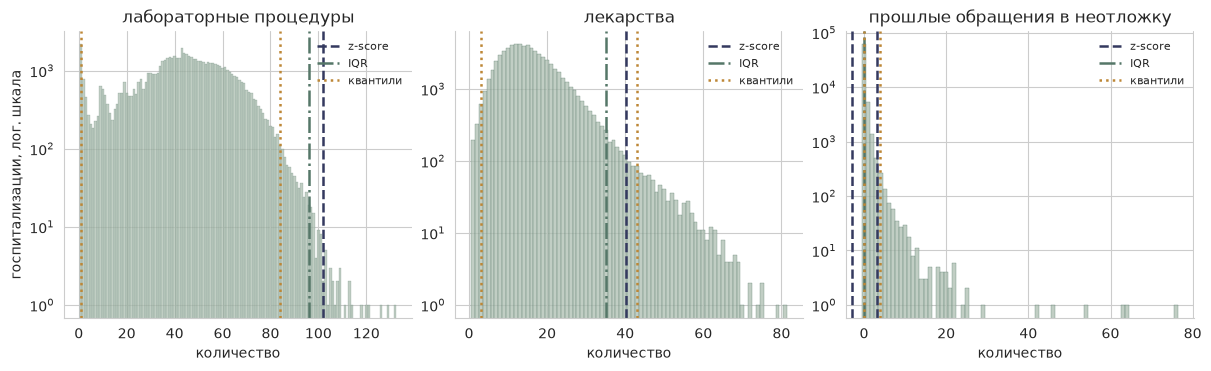

                      признак  правило  нижняя  верхняя  отмечено   доля
       лабораторные процедуры  z-score  -15.98   101.83        29  0.04%
       лабораторные процедуры      IQR   -8.00    96.00        83  0.12%
       лабораторные процедуры квантили    1.00    84.00       652  0.93%
                    лекарства  z-score   -8.33    40.29       927  1.33%
                    лекарства      IQR   -5.00    35.00      1722  2.46%
                    лекарства квантили    3.00    43.00      1185  1.69%
прошлые обращения в неотложку  z-score   -2.84     3.25       706  1.01%
прошлые обращения в неотложку      IQR    0.00     0.00      7846 11.22%
прошлые обращения в неотложку квантили    0.00     4.00       437  0.62%


In [7]:
rule_features = {**features, "number_emergency": "прошлые обращения в неотложку"}
rule_data = train[list(rule_features)]
means, stds = rule_data.mean(), rule_data.std(ddof=0)
assert stds.gt(0).all()
q1, q3 = rule_data.quantile(0.25), rule_data.quantile(0.75)
rule_iqr = q3 - q1
rule_colors = {"z-score": "#34395F", "IQR": "#557768", "квантили": "#BD8736"}
rule_styles = {"z-score": "--", "IQR": "-.", "квантили": ":"}
bounds = {
    "z-score": (means - 3 * stds, means + 3 * stds),
    "IQR": (q1 - 1.5 * rule_iqr, q3 + 1.5 * rule_iqr),
    "квантили": (low[list(rule_features)], high[list(rule_features)]),
}
natural_flags = {}
bound_rows = []
with sns.axes_style("whitegrid", {"axes.grid.axis": "y"}):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
    for (feature, label), ax in zip(rule_features.items(), axes, strict=True):
        values = rule_data[feature]
        sns.histplot(x=values, discrete=True, color="#ACBEB0", edgecolor="#557768", ax=ax)
        xmin, xmax = ax.get_xlim()
        ax.set_yscale("log")
        for method, (lower, upper) in bounds.items():
            lo, hi = lower[feature], upper[feature]
            flag = values.lt(lo) | values.gt(hi)
            natural_flags[feature, method] = flag
            bound_rows.append({
                "признак": label, "правило": method, "нижняя": lo, "верхняя": hi,
                "отмечено": flag.sum(), "доля": flag.mean(),
            })
            visible = [limit for limit in dict.fromkeys([lo, hi]) if xmin <= limit <= xmax]
            for i, limit in enumerate(visible):
                ax.axvline(limit, color=rule_colors[method], linestyle=rule_styles[method],
                           linewidth=1.8, label=method if i == 0 else None)
        ax.set(xlim=(xmin, xmax), title=label, xlabel="количество")
        ax.set_ylabel("госпитализации, лог. шкала" if ax is axes[0] else "")
        ax.legend(frameon=False, fontsize=8)
    sns.despine(fig=fig)
plt.show()

print(pd.DataFrame(bound_rows).round({"нижняя": 2, "верхняя": 2}).to_string(
    index=False, formatters={"доля": "{:.2%}".format},
))


#### Одинаковый бюджет и примеры расхождений

Для каждого признака берём по 1% строк на правило. z-score ранжирует по расстоянию от среднего в стандартных отклонениях. IQR ранжирует по выходу за границы, делённому на IQR. Квантили используют тот же балл выхода за границы, что и выше. Если положительных баллов меньше бюджета, остаток заполняют строки с нулевым баллом в фиксированном порядке. Показываем это отдельно. При нулевом IQR пропускаем рейтинг IQR.

In [8]:
budget_rows = []
examples_by_rule = []
for feature, label in rule_features.items():
    values = rule_data[feature]
    scores = {"z-score": ((values - means[feature]) / stds[feature]).abs()}
    method_scales = {"квантили": span[feature]}
    if rule_iqr[feature] > 0:
        method_scales["IQR"] = rule_iqr[feature]
    for method, scale in method_scales.items():
        lower, upper = bounds[method]
        scores[method] = pd.concat([lower[feature] - values, values - upper[feature]], axis=1).max(axis=1).clip(lower=0) / scale

    ranked = {method: top_rows(score) for method, score in scores.items()}
    membership = pd.DataFrame(
        {method: values.index.isin(rows) for method, rows in ranked.items()}, index=values.index,
    )
    assert membership.sum().eq(n_flagged).all()
    for method, rows in ranked.items():
        score = scores[method]
        cutoff = score.loc[rows].min()
        exclusive = rows.intersection(membership.index[membership.sum(axis=1).eq(1)])
        budget_rows.append({
            "признак": label, "правило": method,
            "совпали с квантилями": len(rows.intersection(ranked["квантили"])),
            "строк с баллом на границе": score.eq(cutoff).sum(),
            "в топе внутри естественных границ": (~natural_flags[feature, method].loc[rows]).sum(),
            "доля <30": train.loc[rows, "readmitted_30d"].mean(),
        })
        candidates = exclusive.intersection(values.index[natural_flags[feature, method]])
        example_rows = score.loc[candidates].nlargest(1).index
        if len(example_rows):
            examples_by_rule.append(train.loc[example_rows, ["encounter_id", "readmitted"]].assign(
                признак=label, правило=method, значение=values.loc[example_rows],
            ))
    if rule_iqr[feature] == 0:
        print(f"IQR для «{label}» равен нулю, рейтинг пропущен")

print(pd.DataFrame(budget_rows).to_string(index=False, formatters={"доля <30": "{:.1%}".format}))
if examples_by_rule:
    display(pd.concat(examples_by_rule).reset_index(drop=True))
else:
    print("уникальных примеров за естественными границами нет")


IQR для «прошлые обращения в неотложку» равен нулю, рейтинг пропущен
                      признак  правило  совпали с квантилями  строк с баллом на границе  в топе внутри естественных границ доля <30
       лабораторные процедуры  z-score                   653                       2199                                670    12.4%
       лабораторные процедуры квантили                   699                      69292                                 47    12.7%
       лабораторные процедуры      IQR                   136                      69861                                616    11.6%
                    лекарства  z-score                   569                         84                                  0    12.3%
                    лекарства квантили                   699                        259                                  0    11.2%
                    лекарства      IQR                   569                         84                                  0    12.3%
прошлые

,encounter_id,readmitted,признак,правило,значение
0,139943934,>30,лекарства,квантили,1
1,249446148,>30,прошлые обращения в неотложку,z-score,4


**вывод.** Для анализов естественные пороги отметили 29 строк по z-score, 83 по IQR и 652 по квантилям. При бюджете в 699 строк в рейтинг попадают и записи внутри естественных границ, поэтому совпадение списков нужно читать вместе с числом таких записей. Для прошлых обращений в неотложку IQR равен нулю: правило отмечает все 7 846 строк, где число обращений больше нуля.